In [1]:
import io
import math
import os
import random
import subprocess
import time
from functools import partial


import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from einops import rearrange
from einops.layers.torch import Rearrange

# ==========================================
# Strict Reproducibility / Determinism Setup
# ==========================================
SEED_VALUE = 42

# 1. Python & NumPy seeds
random.seed(SEED_VALUE)
np.random.seed(SEED_VALUE)

# 2. PyTorch CPU & GPU seeds
torch.manual_seed(SEED_VALUE)
torch.cuda.manual_seed(SEED_VALUE)
torch.cuda.manual_seed_all(SEED_VALUE)

# 3. CuDNN Determinism Settings
# Note: benchmark must be False and deterministic must be True 
# to guarantee identical outputs across multiple runs on a GPU.
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

# 4. Enforce strict deterministic algorithms in PyTorch
torch.use_deterministic_algorithms(True, warn_only=True)

In [2]:

# 1. Clone the repository into a temporary folder
repo_url = "https://github.com/Graham-Brady-Research-Group/AutoregressiveEnsemble_SpatioTemporal_Evolution.git"
temp_dir = "temp_repo_files"

if os.path.exists(temp_dir):
    subprocess.run(["rm", "-rf", temp_dir])

print("Cloning repository...")
subprocess.run(["git", "clone", repo_url, temp_dir])

# 2. Move all .py files from the cloned repo to your current working directory
py_files_moved = 0
for root, dirs, files in os.walk(temp_dir):
    # Skip the .git folder itself
    if ".git" in root:
        continue
    for file in files:
        if file.endswith(".py"):
            src_path = os.path.join(root, file)
            dest_path = file  # Saves directly to your current working directory

            # If there are duplicate filenames in subfolders, you can prefix them or just copy
            subprocess.run(["cp", src_path, dest_path])
            print(f"Downloaded/Copied: {file}")
            py_files_moved += 1

# 3. Clean up the temporary directory
subprocess.run(["rm", "-rf", temp_dir])
print(f"\nSuccessfully brought {py_files_moved} Python file(s) into your working directory!")

Cloning repository...
Downloaded/Copied: loadpath_gen.py
Downloaded/Copied: unet_2d.py
Downloaded/Copied: main.py
Downloaded/Copied: viz_utils.py
Downloaded/Copied: dataprocessor_loadpathvar.py
Downloaded/Copied: inference.py


Cloning into 'temp_repo_files'...


Downloaded/Copied: utils.py

Successfully brought 7 Python file(s) into your working directory!


In [3]:
from unet_2d import Unet2D

In [4]:
def generate_pde_data(num_samples=1000, time_steps=50, grid_points=128):
    """Generates 1D smooth wave propagation trajectories."""
    x = np.linspace(0, 2 * np.pi, grid_points)
    t = np.linspace(0, 2, time_steps)
    data = []

    for _ in range(num_samples):
        # Random wave parameters
        a = np.random.uniform(0.5, 1.5)
        k = np.random.choice([1, 2, 3])
        c = np.random.uniform(0.5, 1.5)
        
        u = np.zeros((time_steps, grid_points))
        for t_idx, t_val in enumerate(t):
            u[t_idx, :] = a * np.sin(k * (x - c * t_val)) + 0.5 * np.cos(2 * k * (x - c * t_val))
        data.append(u)

    return torch.tensor(np.array(data), dtype=torch.float32)

In [5]:
def prepare_training_pairs(pde_trajectories: torch.Tensor, history_steps: int = 10):
    X, Y = [], []
    num_samples, total_time, grid_size = pde_trajectories.shape

    for t in range(history_steps, total_time):
        x_seq = pde_trajectories[:, t - history_steps : t, :].permute(0, 2, 1)
        y_seq = pde_trajectories[:, t : t + 1, :].permute(0, 2, 1)
        X.append(x_seq)
        Y.append(y_seq)

    X = torch.cat(X, dim=0)
    Y = torch.cat(Y, dim=0)
    return X, Y

In [6]:
def plot_trajectory_summary(sample_idx, title_prefix, mse_val, mae_val, r2_val, 
                            ground_truth_np, predicted_np, history_steps, grid_points):
    actual_sample = ground_truth_np[sample_idx]
    predicted_sample = predicted_np[sample_idx]

    fig = plt.figure(figsize=(15, 10))
    fig.suptitle(
        f"{title_prefix} (Sample #{sample_idx + 1})\n"
        f"MSE: {mse_val:.6f} | MAE: {mae_val:.6f} | R² Score: {r2_val:.4f}",
        fontsize=14, fontweight='bold'
    )

    # 1. Heatmap: Ground Truth
    ax1 = fig.add_subplot(2, 2, 1)
    im1 = ax1.imshow(actual_sample, aspect='auto', cmap='jet', origin='lower')
    ax1.set_title("Actual Ground Truth (Space-Time)")
    ax1.set_xlabel("Spatial Grid (x)")
    ax1.set_ylabel("Time Step (t)")
    ax1.axhline(y=history_steps - 0.5, color='black', linestyle='--', label=f'End of initial {history_steps} steps')
    fig.colorbar(im1, ax=ax1)

    # 2. Heatmap: FNO Auto-regressive Prediction
    ax2 = fig.add_subplot(2, 2, 2)
    im2 = ax2.imshow(predicted_sample, aspect='auto', cmap='jet', origin='lower')
    ax2.set_title("FNO Prediction (Auto-regressive)")
    ax2.set_xlabel("Spatial Grid (x)")
    ax2.set_ylabel("Time Step (t)")
    ax2.axhline(y=history_steps - 0.5, color='black', linestyle='--', label=f'End of initial {history_steps} steps')
    fig.colorbar(im2, ax=ax2)

    # 3. Absolute Error Heatmap
    ax3 = fig.add_subplot(2, 2, 3)
    error_sample = np.abs(actual_sample - predicted_sample)
    im3 = ax3.imshow(error_sample, aspect='auto', cmap='Reds', origin='lower')
    ax3.set_title("Absolute Error |Actual - Predicted|")
    ax3.set_xlabel("Spatial Grid (x)")
    ax3.set_ylabel("Time Step (t)")
    fig.colorbar(im3, ax=ax3)

    # 4. Snapshot profiles at specific future time steps
    ax4 = fig.add_subplot(2, 2, 4)
    x_axis = np.linspace(0, 1, grid_points)
    time_snapshots = [history_steps + 2, 25, 45]  # Time steps to view cross-sections

    for t_snap in time_snapshots:
        ax4.plot(x_axis, actual_sample[t_snap], label=f"Actual (t={t_snap})", linestyle='--')
        ax4.plot(x_axis, predicted_sample[t_snap], label=f"Pred (t={t_snap})")

    ax4.set_title("Spatial Profile Snapshots")
    ax4.set_xlabel("Spatial Grid (x)")
    ax4.set_ylabel("u(x, t)")
    ax4.legend(loc='upper right', fontsize='small')
    ax4.grid(True)

    plt.tight_layout()
    plt.show()

In [7]:



def conv_forward_pass_unet(model, x_batch, history_steps, ip_time_dim, device):
    """
    Adapter function to format 1D PDE inputs into a 2D spatial representation
    compatible with Unet2D downsampling blocks.
    """
    batch_size = x_batch.shape[0]
    channels = 3
    H, W = 8, 16  # 8 * 16 = 128 grid points

    # Extract latest time step across all spatial points: [Batch, 128]
    x_latest = x_batch[:, :, -1] if x_batch.ndim == 3 else x_batch

    # Reshape to [Batch, 1, 8, 16] and expand channels to [Batch, 3, 8, 16]
    x_spatial = x_latest.view(batch_size, 1, H, W)
    x_spatial = x_spatial.repeat(1, channels, 1, 1).to(device)

    # Temporal conditioning vector: [Batch, ip_time_dim]
    if x_batch.ndim == 3:
        t_cond = x_batch[:, 0, :ip_time_dim].to(device)
    else:
        t_cond = torch.zeros(batch_size, ip_time_dim, device=device)

    return model(x_spatial, t_cond)


def train_single_model(model_idx, train_loader, epochs, channels, ip_time_dim, history_steps, device, seed):
    """
    Utility function to instantiate and train a single Unet2D model instance 
    with a distinct random weight initialization seed.
    """
    # Set seed for reproducible weight initialization per model variant
    torch.manual_seed(seed)
    
    model = Unet2D(
        dim=16,
        out_dim=1,
        dim_mults=(1, 2, 4),
        channels=channels,
        ip_time_dim=ip_time_dim
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=2e-3, weight_decay=1e-4)
    criterion = nn.MSELoss()

    model.train()
    print(f"\n--- Training Model {model_idx + 1}/4 (Seed: {seed}) ---")
    
    start_time = time.time()
    for epoch in range(1, epochs + 1):
        total_loss = 0.0
        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device).view(-1, 1, 8, 16)

            optimizer.zero_grad()
            preds = conv_forward_pass_unet(model, x_batch, history_steps, ip_time_dim, device)
            loss = criterion(preds, y_batch)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        if epoch % 1 == 0 or epoch == 1:
            print(f"Model {model_idx + 1} | Epoch [{epoch}/{epochs}] - Loss: {avg_loss:.6f}")

    elapsed_time = time.time() - start_time
    print(f"Model {model_idx + 1} training complete in {elapsed_time:.2f}s")
    
    return model

Using device: cuda

Starting training for 4 models (100 epochs each)...

--- Training Model 1/4 (Seed: 42) ---
Model 1 | Epoch [1/100] - Loss: 0.005820
Model 1 | Epoch [2/100] - Loss: 0.000737
Model 1 | Epoch [3/100] - Loss: 0.000546
Model 1 | Epoch [4/100] - Loss: 0.000476
Model 1 | Epoch [5/100] - Loss: 0.000438
Model 1 | Epoch [6/100] - Loss: 0.000426
Model 1 | Epoch [7/100] - Loss: 0.000412
Model 1 | Epoch [8/100] - Loss: 0.000410
Model 1 | Epoch [9/100] - Loss: 0.000412
Model 1 | Epoch [10/100] - Loss: 0.000370
Model 1 | Epoch [11/100] - Loss: 0.000370
Model 1 | Epoch [12/100] - Loss: 0.000343
Model 1 | Epoch [13/100] - Loss: 0.000360
Model 1 | Epoch [14/100] - Loss: 0.000331
Model 1 | Epoch [15/100] - Loss: 0.000344
Model 1 | Epoch [16/100] - Loss: 0.000306
Model 1 | Epoch [17/100] - Loss: 0.000314
Model 1 | Epoch [18/100] - Loss: 0.000314
Model 1 | Epoch [19/100] - Loss: 0.000312
Model 1 | Epoch [20/100] - Loss: 0.000296
Model 1 | Epoch [21/100] - Loss: 0.000310
Model 1 | Epoch 

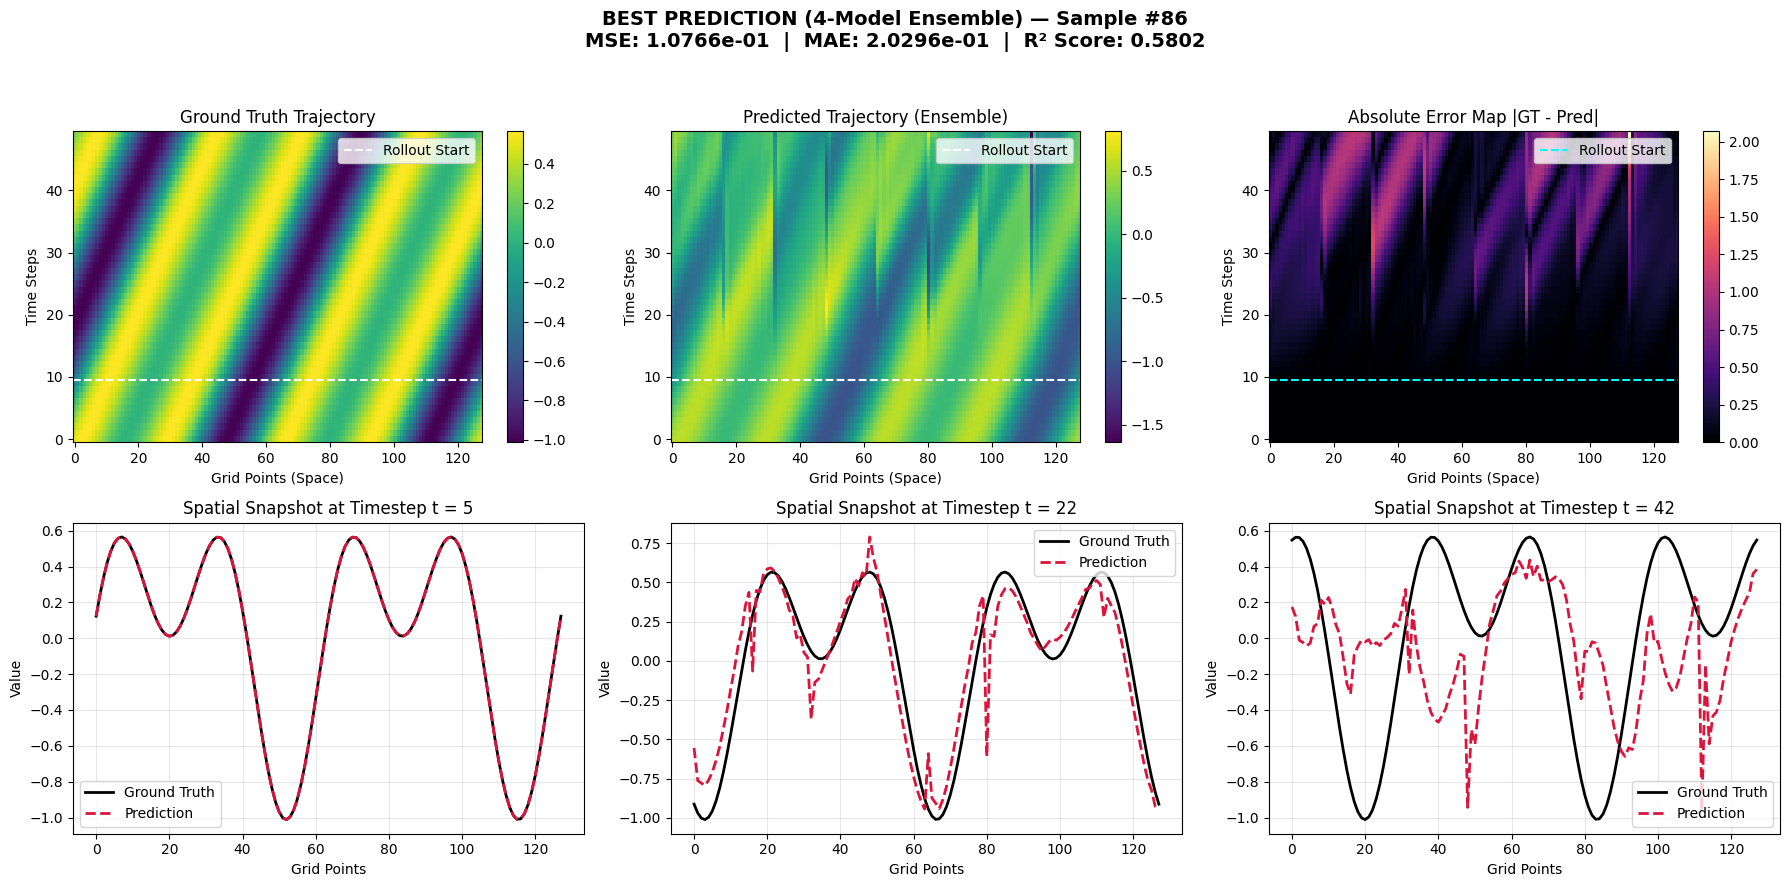

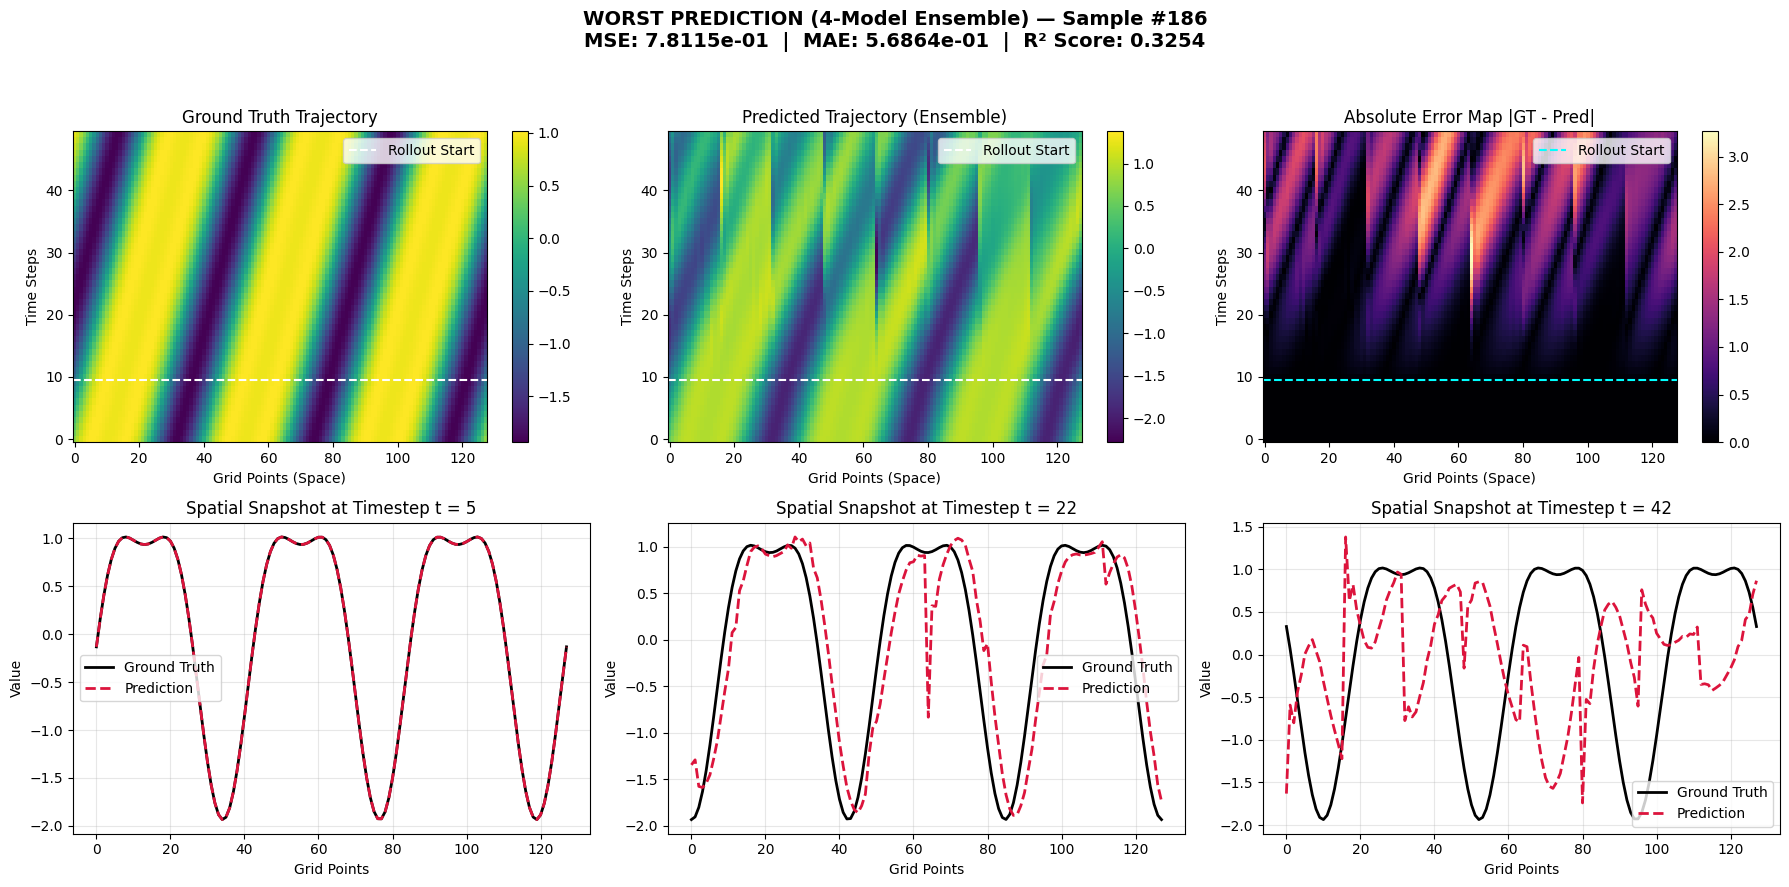

In [8]:
def plot_trajectory_summary(sample_idx, tag, mse, mae, r2, gt_arr, pred_arr, history_steps, grid_points):
    """Plots 2D spatiotemporal heatmaps, error map, and time-slice profile snapshots."""
    gt = gt_arr[sample_idx]
    pred = pred_arr[sample_idx]
    abs_err = np.abs(gt - pred)

    fig = plt.figure(figsize=(18, 9))
    fig.suptitle(
        f"{tag} — Sample #{sample_idx + 1}\n"
        f"MSE: {mse:.4e}  |  MAE: {mae:.4e}  |  R² Score: {r2:.4f}",
        fontsize=14, fontweight='bold', y=0.98
    )

    # 1. Ground Truth Heatmap
    ax1 = plt.subplot(2, 3, 1)
    im1 = ax1.imshow(gt, aspect='auto', cmap='viridis', origin='lower')
    ax1.set_title("Ground Truth Trajectory")
    ax1.set_xlabel("Grid Points (Space)")
    ax1.set_ylabel("Time Steps")
    ax1.axhline(y=history_steps - 0.5, color='white', linestyle='--', linewidth=1.5, label='Rollout Start')
    ax1.legend(loc='upper right')
    plt.colorbar(im1, ax=ax1)

    # 2. Predicted Heatmap
    ax2 = plt.subplot(2, 3, 2)
    im2 = ax2.imshow(pred, aspect='auto', cmap='viridis', origin='lower')
    ax2.set_title("Predicted Trajectory (Ensemble)")
    ax2.set_xlabel("Grid Points (Space)")
    ax2.set_ylabel("Time Steps")
    ax2.axhline(y=history_steps - 0.5, color='white', linestyle='--', linewidth=1.5, label='Rollout Start')
    ax2.legend(loc='upper right')
    plt.colorbar(im2, ax=ax2)

    # 3. Absolute Error Heatmap
    ax3 = plt.subplot(2, 3, 3)
    im3 = ax3.imshow(abs_err, aspect='auto', cmap='magma', origin='lower')
    ax3.set_title("Absolute Error Map |GT - Pred|")
    ax3.set_xlabel("Grid Points (Space)")
    ax3.set_ylabel("Time Steps")
    ax3.axhline(y=history_steps - 0.5, color='cyan', linestyle='--', linewidth=1.5, label='Rollout Start')
    ax3.legend(loc='upper right')
    plt.colorbar(im3, ax=ax3)

    # 4. Spatial Snapshot Profiles across time steps
    t_total = gt.shape[0]
    snapshots = [
        int(history_steps * 0.5),                    # Mid-history
        history_steps + int((t_total - history_steps) * 0.3),  # Early rollout
        history_steps + int((t_total - history_steps) * 0.8)   # Late rollout
    ]

    for i, t_step in enumerate(snapshots):
        ax = plt.subplot(2, 3, 4 + i)
        ax.plot(gt[t_step], label='Ground Truth', color='black', linewidth=2)
        ax.plot(pred[t_step], label='Prediction', color='crimson', linestyle='--', linewidth=2)
        ax.set_title(f"Spatial Snapshot at Timestep t = {t_step}")
        ax.set_xlabel("Grid Points")
        ax.set_ylabel("Value")
        ax.grid(True, alpha=0.3)
        ax.legend()

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()


def main():
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}\n")

    num_pdes = 1000
    time_steps = 50
    grid_points = 128
    history_steps = 10
    ip_time_dim = 10
    channels = 3
    training_amount = int(0.8 * num_pdes)
    num_models = 4
    epochs = 100

    # 1. Generate synthetic PDE solutions
    all_pde_data = generate_pde_data(num_pdes, time_steps, grid_points)

    train_data = all_pde_data[:training_amount]
    test_data = all_pde_data[training_amount:]

    X_train, Y_train = prepare_training_pairs(train_data, history_steps=history_steps)
    train_dataset = torch.utils.data.TensorDataset(X_train, Y_train)
    train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)

    # 2. Train 4 models with different weight initialization seeds
    models = []
    seeds = [42, 123, 456, 789]

    print(f"Starting training for {num_models} models ({epochs} epochs each)...")
    total_train_start = time.perf_counter()

    for i in range(num_models):
        model = train_single_model(
            model_idx=i,
            train_loader=train_loader,
            epochs=epochs,
            channels=channels,
            ip_time_dim=ip_time_dim,
            history_steps=history_steps,
            device=device,
            seed=seeds[i]
        )
        models.append(model)

    total_train_time = time.perf_counter() - total_train_start
    train_mins, train_secs = divmod(total_train_time, 60)

    # 3. Ensemble Autoregressive Rollout Evaluation on Test Set
    rollout_steps = time_steps - history_steps
    batch_size = test_data.shape[0]

    # Store predicted trajectories for each of the 4 models
    # Shape of each model output: [batch_size, rollout_steps, grid_points]
    all_model_predictions = []

    print("\nRunning Autoregressive Rollouts across ensemble models...")

    for idx, model in enumerate(models):
        model.eval()
        # Reset current history window for this model
        current_history = test_data[:, :history_steps, :].permute(0, 2, 1).clone().to(device)
        model_frames = []

        with torch.no_grad():
            for step in range(rollout_steps):
                pred_next = conv_forward_pass_unet(model, current_history, history_steps, ip_time_dim, device)
                pred_1d = pred_next.view(-1, grid_points, 1)  # [batch, 128, 1]
                model_frames.append(pred_1d)

                # Update sliding history window autoregressively for this model
                current_history = torch.cat([current_history[:, :, 1:], pred_1d], dim=2)

        # Concatenate rollout steps along time dim: [batch, grid_points, rollout_steps] -> permute to [batch, rollout_steps, grid_points]
        model_rollout = torch.cat(model_frames, dim=2).permute(0, 2, 1).cpu()
        all_model_predictions.append(model_rollout)

    # 4. Average predictions across the 4 weight variants
    # Stack along new dimension 0: [4, batch, rollout_steps, grid_points]
    stacked_predictions = torch.stack(all_model_predictions, dim=0)

    # Take mean across the 4 model weight predictions
    ensemble_predictions_only = torch.mean(stacked_predictions, dim=0)  # [batch, rollout_steps, grid_points]

    # Prepend initial ground truth history steps to complete trajectory
    initial_frames = test_data[:, :history_steps, :]
    full_predicted_trajectories = torch.cat([initial_frames, ensemble_predictions_only], dim=1)

    # Print total ensemble training duration
    print(f"\nAll {num_models} models trained in {total_train_time:.2f}s ({int(train_mins)}m {train_secs:.2f}s).")

    # 5. Evaluate Trajectory Metrics on Ensembled Output
    ground_truth_np = test_data.numpy()
    predicted_np = full_predicted_trajectories.numpy()

    test_mse = np.mean((predicted_np[:, history_steps:, :] - ground_truth_np[:, history_steps:, :]) ** 2)
    print(f"4-Model Ensemble Rollout MSE on {int(0.2 * num_pdes)} Test Trajectories: {test_mse:.4e}")

    mse_per_sample = np.mean((ground_truth_np - predicted_np) ** 2, axis=(1, 2))
    mae_per_sample = np.mean(np.abs(ground_truth_np - predicted_np), axis=(1, 2))

    r2_per_sample = []
    for i in range(len(ground_truth_np)):
        y_true = ground_truth_np[i].flatten()
        y_pred = predicted_np[i].flatten()
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
        r2 = 1.0 - (ss_res / (ss_tot + 1e-8))
        r2_per_sample.append(r2)
    r2_per_sample = np.array(r2_per_sample)

    best_idx = int(np.argmin(mse_per_sample))
    worst_idx = int(np.argmax(mse_per_sample))

    print(f"Best Test Trajectory Index:  #{best_idx + 1} | MSE: {mse_per_sample[best_idx]:.4e}")
    print(f"Worst Test Trajectory Index: #{worst_idx + 1} | MSE: {mse_per_sample[worst_idx]:.4e}\n")

    # Plot Best & Worst Trajectories
    plot_trajectory_summary(
        best_idx, "BEST PREDICTION (4-Model Ensemble)", 
        mse_per_sample[best_idx], mae_per_sample[best_idx], r2_per_sample[best_idx],
        ground_truth_np, predicted_np, history_steps, grid_points
    )

    plot_trajectory_summary(
        worst_idx, "WORST PREDICTION (4-Model Ensemble)", 
        mse_per_sample[worst_idx], mae_per_sample[worst_idx], r2_per_sample[worst_idx],
        ground_truth_np, predicted_np, history_steps, grid_points
    )


if __name__ == "__main__":
    main()